# Short-Term Boiler Sensor Forecast

This notebook forecasts `ZZQBCHLL.AV_0#`, catalogued as **Main steam flow rate after compensation**, from `data.csv`. This is a key boiler output measurement selected for its process relevance; it is not claimed to be a statistically ranked "most important" sensor. The readings are aggregated to one-minute means and used for a short, 60-minute-ahead forecast.

The available record spans only a few days. Accordingly, this notebook does not infer weekly or annual seasonality, causal relationships, or safe operating limits. The forecast is an exploratory baseline and should not be used as an operating control or safety decision.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TARGET_COLUMN = "ZZQBCHLL.AV_0#"
TARGET_LABEL = "Main steam flow rate after compensation"
RESAMPLE_FREQUENCY = "1min"
FORECAST_STEPS = 60
LAGS = (1, 2, 3, 5, 10, 15, 30, 60)

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for folder in (start, *start.parents):
        if all((folder / name).is_file() for name in ("data.csv", "columns.csv")):
            return folder
    raise FileNotFoundError(
        "Could not locate data.csv and columns.csv from the current directory or its parents."
    )

PROJECT_DIR = find_project_root()
print(f"Project directory: {PROJECT_DIR}")

Project directory: c:\Users\sulaiman.at\Documents\GitHub\Industrial-Boiler-Operations-Analytics


## Load and check the source data

The sensor label is checked against `columns.csv`. Invalid timestamps and target readings are counted explicitly. The source is sorted by time, then resampled to one-minute means; missing one-minute bins are not interpolated because that would invent measurements.

In [2]:
data = pd.read_csv(PROJECT_DIR / "data.csv")
catalog = pd.read_csv(PROJECT_DIR / "columns.csv")

if "date" not in data.columns:
    raise KeyError("data.csv must contain a 'date' timestamp column.")
if TARGET_COLUMN not in data.columns:
    raise KeyError(f"Expected forecast sensor {TARGET_COLUMN!r} in data.csv.")

if "Variant" not in catalog.columns or "Attribute name" not in catalog.columns:
    raise KeyError("columns.csv must contain 'Variant' and 'Attribute name' columns.")
catalog_names = catalog["Variant"].fillna("").astype(str).str.strip()
normalized_target = TARGET_COLUMN.removesuffix("#")
catalog_match = catalog.loc[catalog_names.eq(normalized_target)]
if catalog_match.empty:
    raise ValueError(f"{TARGET_COLUMN!r} was not found in columns.csv metadata.")
TARGET_LABEL = str(catalog_match.iloc[0]["Attribute name"])
print(f"Sensor: {TARGET_LABEL} ({TARGET_COLUMN})")

timestamps = pd.to_datetime(data["date"], errors="coerce")
values = pd.to_numeric(data[TARGET_COLUMN], errors="coerce")
invalid_timestamps = int(timestamps.isna().sum())
invalid_readings = int(values.isna().sum())
valid = timestamps.notna() & values.notna()
observations = pd.DataFrame({"timestamp": timestamps[valid], "reading": values[valid]})
observations = observations.sort_values("timestamp").set_index("timestamp")
if observations.empty:
    raise ValueError("No valid timestamped target readings remain after parsing.")

source_intervals = observations.index.to_series().diff().dropna().dt.total_seconds()
print(f"Source rows: {len(data):,}; valid timestamped target rows: {len(observations):,}")
print(f"Invalid timestamps: {invalid_timestamps:,}; invalid target readings: {invalid_readings:,}")
print(f"Time coverage: {observations.index.min()} to {observations.index.max()}")
if not source_intervals.empty:
    print(f"Median source sampling interval: {source_intervals.median():g} seconds")

minute_readings = observations["reading"].resample(RESAMPLE_FREQUENCY).mean()
missing_minutes = minute_readings.index[minute_readings.isna()]
if not missing_minutes.empty:
    raise ValueError(
        f"Found {len(missing_minutes)} empty one-minute bins. Review source gaps before forecasting; "
        "this notebook does not fill missing readings."
    )
if len(minute_readings) <= max(LAGS) + FORECAST_STEPS:
    raise ValueError("Not enough one-minute readings for the selected lags and 60-minute holdout.")

print(f"One-minute readings: {len(minute_readings):,}; forecast horizon: {FORECAST_STEPS} minutes")
display(minute_readings.describe().to_frame(name="reading"))

Sensor: Main steam flow rate after compensation (ZZQBCHLL.AV_0#)
Source rows: 86,400; valid timestamped target rows: 86,400
Invalid timestamps: 0; invalid target readings: 0
Time coverage: 2022-03-27 14:28:54 to 2022-04-01 14:28:49
Median source sampling interval: 5 seconds
One-minute readings: 7,201; forecast horizon: 60 minutes


,reading
count,7201.000000
mean,59.762054
std,2.362196
min,51.458333
25%,58.421667
50%,59.853333
75%,61.345000
max,70.591667


## Inspect the target history

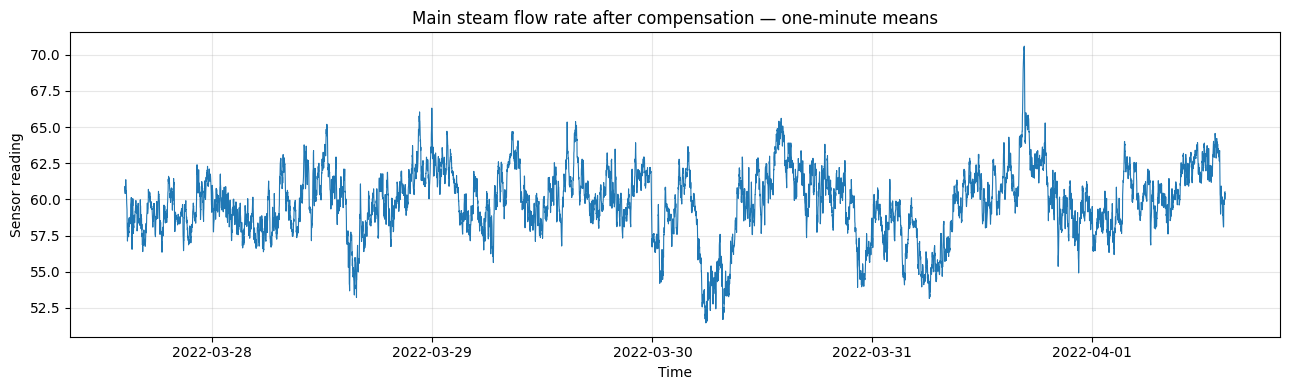

In [3]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(minute_readings.index, minute_readings, linewidth=0.8)
ax.set(title=f"{TARGET_LABEL} — one-minute means", xlabel="Time", ylabel="Sensor reading")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Chronological holdout and baseline comparison

The final hour is held out for evaluation. An autoregressive least-squares model uses readings from the preceding 1, 2, 3, 5, 10, 15, 30, and 60 minutes. Both that model and the persistence baseline (repeat the last training reading) are forecast recursively: predictions, not actual holdout readings, are fed back at every step. This avoids leaking the holdout into later predictions.

In [4]:
def lagged_design(values, lags):
    values = np.asarray(values, dtype=float)
    first_row = max(lags)
    if len(values) <= first_row:
        raise ValueError("Training data is too short to construct the requested lagged features.")
    features = np.column_stack(
        [np.ones(len(values) - first_row)]
        + [values[first_row - lag : len(values) - lag] for lag in lags]
    )
    return features, values[first_row:]

def fit_autoregression(values, lags):
    features, targets = lagged_design(values, lags)
    coefficients, _, _, _ = np.linalg.lstsq(features, targets, rcond=None)
    return coefficients

def recursive_forecast(history, coefficients, lags, steps):
    history = list(np.asarray(history, dtype=float))
    if len(history) < max(lags):
        raise ValueError("Forecast history is shorter than the largest model lag.")
    forecasts = []
    for _ in range(steps):
        features = np.array([1.0] + [history[-lag] for lag in lags])
        prediction = float(features @ coefficients)
        forecasts.append(prediction)
        history.append(prediction)
    return np.asarray(forecasts)

def forecast_metrics(actual, predicted):
    errors = np.asarray(actual, dtype=float) - np.asarray(predicted, dtype=float)
    return {"MAE": float(np.mean(np.abs(errors))), "RMSE": float(np.sqrt(np.mean(errors**2)))}

series = minute_readings.astype(float)
train = series.iloc[:-FORECAST_STEPS]
holdout = series.iloc[-FORECAST_STEPS:]
validation_coefficients = fit_autoregression(train.to_numpy(), LAGS)
validation_forecast = recursive_forecast(
    train.to_numpy(), validation_coefficients, LAGS, FORECAST_STEPS
)
persistence_forecast = np.repeat(float(train.iloc[-1]), FORECAST_STEPS)
actual_holdout = holdout.to_numpy()

validation_errors = actual_holdout - validation_forecast
metrics = pd.DataFrame(
    {
        "Autoregressive least squares": forecast_metrics(actual_holdout, validation_forecast),
        "Persistence baseline": forecast_metrics(actual_holdout, persistence_forecast),
    }
).T
display(metrics)
print(f"Validation period: {holdout.index[0]} to {holdout.index[-1]}")

,MAE,RMSE
Autoregressive least squares,1.623658,2.027789
Persistence baseline,2.528928,3.150603


Validation period: 2022-04-01 13:29:00 to 2022-04-01 14:28:00


The single held-out hour is a useful short-horizon check, not broad evidence of future accuracy. If the autoregressive model does not outperform persistence, prefer the simpler baseline until more data or a better validated model is available.

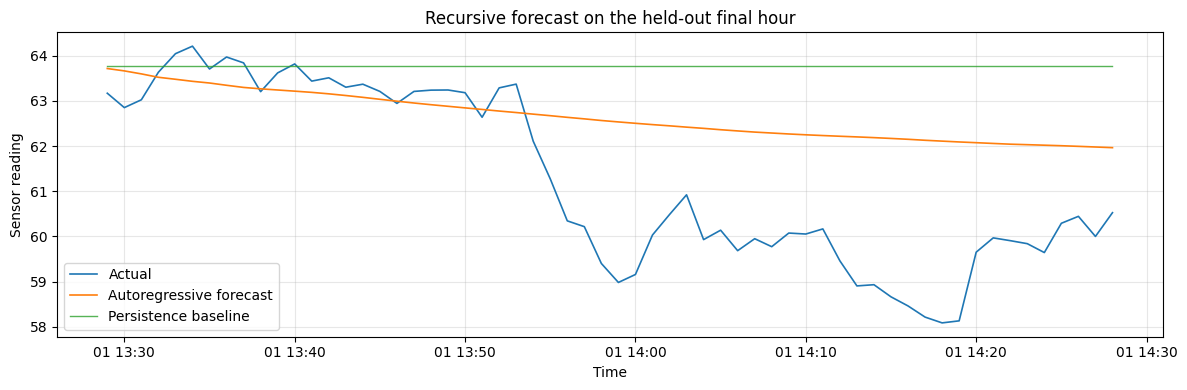

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(holdout.index, actual_holdout, label="Actual", linewidth=1.2)
ax.plot(holdout.index, validation_forecast, label="Autoregressive forecast", linewidth=1.2)
ax.plot(holdout.index, persistence_forecast, label="Persistence baseline", linewidth=1.0, alpha=0.8)
ax.set(title="Recursive forecast on the held-out final hour", xlabel="Time", ylabel="Sensor reading")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Forecast the next 60 minutes

The autoregression is refit on all observed one-minute readings. The shaded band uses the 90th percentile of absolute errors from the recursive validation hour, applied symmetrically at each future step. This is a simple empirical heuristic, **not** a calibrated or horizon-specific prediction interval.

Symmetric empirical 90th-percentile absolute validation error: 3.362


,forecast,heuristic_lower,heuristic_upper
timestamp,,,
2022-04-01 14:29:00,60.372791,57.010638,63.734943
2022-04-01 14:30:00,60.435712,57.073559,63.797864
2022-04-01 14:31:00,60.365876,57.003723,63.728028
2022-04-01 14:32:00,60.324171,56.962018,63.686323
2022-04-01 14:33:00,60.271534,56.909382,63.633687
2022-04-01 14:34:00,60.224371,56.862218,63.586523
2022-04-01 14:35:00,60.219947,56.857795,63.582100
2022-04-01 14:36:00,60.229529,56.867377,63.591682
2022-04-01 14:37:00,60.236810,56.874657,63.598962


,forecast,heuristic_lower,heuristic_upper
timestamp,,,
2022-04-01 15:24:00,60.136268,56.774115,63.498420
2022-04-01 15:25:00,60.135795,56.773642,63.497947
2022-04-01 15:26:00,60.135731,56.773579,63.497884
2022-04-01 15:27:00,60.133330,56.771178,63.495483
2022-04-01 15:28:00,60.133545,56.771393,63.495698


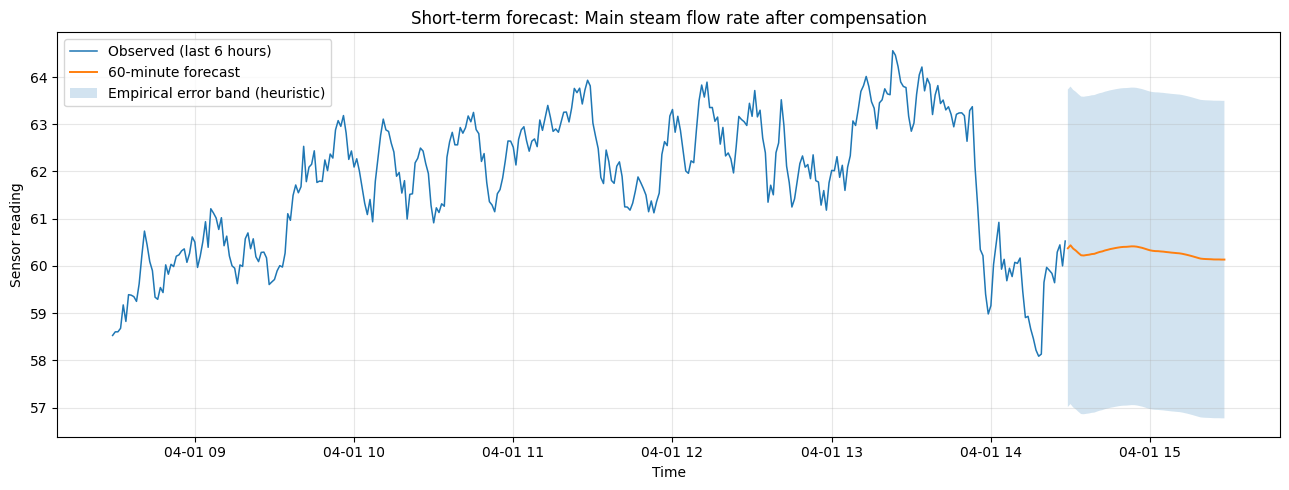

Limitations: this is a one-hour autoregressive extrapolation from a short record. It does not establish weekly/annual seasonality, causal effects, safe limits, or reliable long-range accuracy.


In [6]:
final_coefficients = fit_autoregression(series.to_numpy(), LAGS)
future_values = recursive_forecast(series.to_numpy(), final_coefficients, LAGS, FORECAST_STEPS)
future_index = pd.date_range(
    start=series.index[-1] + pd.Timedelta(minutes=1),
    periods=FORECAST_STEPS,
    freq=RESAMPLE_FREQUENCY,
)
forecast = pd.DataFrame({"forecast": future_values}, index=future_index)
forecast.index.name = "timestamp"

residual_band = float(np.quantile(np.abs(validation_errors), 0.90))
forecast["heuristic_lower"] = forecast["forecast"] - residual_band
forecast["heuristic_upper"] = forecast["forecast"] + residual_band
print(f"Symmetric empirical 90th-percentile absolute validation error: {residual_band:.4g}")
display(forecast.head(10))
display(forecast.tail(5))

fig, ax = plt.subplots(figsize=(13, 5))
recent = series.iloc[-6 * 60 :]
ax.plot(recent.index, recent, label="Observed (last 6 hours)", linewidth=1.1)
ax.plot(forecast.index, forecast["forecast"], label="60-minute forecast", linewidth=1.4)
ax.fill_between(
    forecast.index,
    forecast["heuristic_lower"],
    forecast["heuristic_upper"],
    alpha=0.2,
    label="Empirical error band (heuristic)",
)
ax.set(title=f"Short-term forecast: {TARGET_LABEL}", xlabel="Time", ylabel="Sensor reading")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(
    "Limitations: this is a one-hour autoregressive extrapolation from a short record. "
    "It does not establish weekly/annual seasonality, causal effects, safe limits, or reliable long-range accuracy."
)